# 12 · Set Model pada Item E-commerce Mentah (uji kelayakan jalur relasional)

**Pertanyaan:** apakah record mentah e-commerce menyimpan informasi yang **hilang** dari 50 fitur agregat `ec_*` kita?

Data kita tidak punya hubungan antar-nasabah (notebook sebelumnya: semua ID unik per nasabah), jadi satu-satunya "graph" yang nyata adalah **pohon nasabah → record miliknya**. GNN pada pohon seperti itu, dengan satu lapis, sama dengan **set model**: setiap item diubah menjadi vektor oleh jaringan kecil, lalu vektor-vektor itu digabung (*pooling*) dengan bobot yang **dipelajari**. Fitur agregat kita (rata-rata, maksimum, proporsi, dll.) adalah pooling yang **kita pilih sendiri**. Set model memilih pooling-nya sendiri dari data.

E-commerce dipilih karena tabelnya paling besar (± 22 item per nasabah di data sampel kita, ± 44 di data penuh) dan agregatnya paling "manual".

| Uji | Pertanyaan | Pembanding |
|---|---|---|
| **A. Set vs agregat** | Apakah membaca item mentah mengalahkan 50 fitur `ec_*`? | LightGBM `ec_*` dan regresi logistik `ec_*` (fold sama) |
| **B. Kontrol "informasi sama"** | Apakah set model menambah sesuatu ke LightGBM `ec_*` **lebih banyak** daripada model lain yang hanya melihat agregat yang sama? | blend LightGBM `ec_*` + logreg `ec_*` |
| **C. Stacking bersarang** ⭐ | Apakah skor set model menambah informasi untuk **model lengkap** (semua tabel)? | `lgbm_tuned` + **plasebo** (kolom acak) |
| **D. Ensemble** | Apakah ensemble saat ini naik? | ensemble 4 model (`sub_v4`) |

**Uji C adalah penentu.** Uji A dan B hanya melihat dunia e-commerce. Informasi e-commerce bisa saja sudah tumpang tindih dengan tabel lain: di notebook 08, premium harga e-commerce dan keterlambatan bayar ternyata digerakkan faktor laten yang sama.

**Plasebo di uji C:** menambah satu kolom ke LightGBM mengubah KS walaupun kolom itu tidak berisi informasi, karena pengambilan kolom acak (`colsample_bytree = 0,3`) ikut berubah. Jadi kita juga melatih LightGBM yang sama dengan `set_score` **diacak**. Δ plasebo adalah ukuran noise untuk uji ini.

**Aturan keputusan sama:** jelas (Δ ≥ 0,005) / tipis (Δ ≥ 0,002 dan > noise), semua seed naik.

**Waktu (CPU):** set model ± 1 menit per fold di data sampel (2 core), kira-kira 2× di data penuh (item 2× lebih banyak). Uji C paling mahal: **20 set model per seed** (5 fold luar × 4 fold dalam). Waktu tiap fold dicetak. Setiap run langsung disimpan, jadi kalau sesi terputus, jalankan ulang: run yang sudah ada dimuat dari disk (`SKIP_DONE = True`). Kalau ada GPU (CUDA), otomatis dipakai.

**File:** `seq_models.py` di folder `notebooks/` (bersama `modeling.py`, `features.py`, dst.).

In [1]:
import gc
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

import eda_utils as E
import features as F
import modeling as M
import seq_models as Q

E.setup_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

SEEDS = (42, 7, 2024)          # set model, baseline ec_*, ensemble
STACK_SEEDS = (42, 7, 2024)    # uji C (paling mahal). Untuk uji cepat: (42,)
SKIP_DONE = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| thread CPU torch:", torch.get_num_threads())

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
FEAT, CATS, EC = meta["features"], meta["categorical"], meta["groups"]["ecommerce"]
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
folds = M.fold_table(train)                               # fold identik dengan semua run sebelumnya

CORE = {"lgbm": "lgbm_tuned", "xgb": "xgb_v1", "cat": "cat_v1", "logreg": "logreg_v1"}
RUNS = {k: M.run_from_disk(v, y) for k, v in CORE.items()}
LGB = RUNS["lgbm"]
P_LGB = {k: v for k, v in LGB["params"].items() if k != "random_state"}
print(f"e-commerce: {meta['ecommerce_source']} | {len(EC)} fitur ec_* | lgbm_tuned seed {LGB['seeds']}")

device: cpu | thread CPU torch: 4
e-commerce: ecommerce_transactions.csv | 50 fitur ec_* | lgbm_tuned seed [42, 7, 2024, 11, 99]


## 1. Tabel item

Satu baris = satu item e-commerce **sebelum `decision_datetime`** nasabah itu. Fitur per item:

| Fitur | Isi |
|---|---|
| `lp` | log(harga per unit / median harga kategori sebelum 2025), yaitu premium harga per item |
| `log_unit`, `log_qty`, `log_order_total`, `log_items_in_order` | ukuran transaksi |
| `age_y`, `log_age` | umur transaksi (hari sebelum cutoff) |
| `cancelled` | status order bukan `completed` |
| `cat`, `pay` | kategori produk & metode bayar (embedding yang dipelajari) |

Median kategori sama dengan yang dipakai `ec_*` (dihitung sebelum keputusan pertama), jadi kedua sisi mendapat informasi dasar yang sama. Bedanya hanya **cara meringkas**.

In [2]:
t = time.time()
T = F.load_tables(E.load, E.lazy)
it_tr = Q.item_table(T["ecommerce"], E.load("train_applications"), T["ecom_cat_medians"])
it_te = Q.item_table(T["ecommerce"], E.load("test_applications"), T["ecom_cat_medians"])
A_tr = Q.to_arrays(it_tr, train["customer_id"].to_list())
A_te = Q.to_arrays(it_te, test["customer_id"].to_list())
ARR = Q.concat_arrays(A_tr, A_te)                         # baris test di belakang train
TEST_IDX = np.arange(train.height, train.height + test.height)
print(f"siap dalam {time.time() - t:.0f}s | array item {ARR['num'].shape} | {ARR['num'].nbytes / 1e6:.0f} MB")

def stats(name, a):
    n = a["n_items"]
    return dict(data=name, nasabah=len(n), item=int(n.sum()), rata2=n.mean(), p10=np.percentile(n, 10),
                median=np.median(n), p90=np.percentile(n, 90), maks=int(n.max()), tanpa_item=int((n == 0).sum()))

display(pl.DataFrame([stats("train", A_tr), stats("test", A_te)]).with_columns(pl.col(pl.Float64).round(1)))
print("Contoh item satu nasabah (urut waktu):")
display(it_tr.filter(pl.col("customer_id") == it_tr["customer_id"][0]).head(6).with_columns(pl.col(pl.Float64).round(3)))
del T, it_tr, it_te
gc.collect();

siap dalam 12s | array item (4359817, 8) | 140 MB


data,nasabah,item,rata2,p10,median,p90,maks,tanpa_item
str,i64,i64,f64,f64,f64,f64,i64,i64
"""train""",70000,3049631,43.6,24.0,41.0,67.0,142,0
"""test""",30000,1310186,43.7,24.0,41.0,67.0,132,0


Contoh item satu nasabah (urut waktu):


customer_id,transaction_datetime,lp,log_unit,log_qty,log_order_total,log_items_in_order,age_y,log_age,cancelled,cat,pay
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,i64,i64
"""C_0000026281a8d761""",2023-10-03 12:18:00,-0.312,10.621,0.693,12.689,1.099,1.861,6.523,0.0,0,2
"""C_0000026281a8d761""",2023-10-03 12:18:00,0.552,12.553,0.693,12.689,1.099,1.861,6.523,0.0,1,2
"""C_0000026281a8d761""",2023-12-12 12:17:00,0.734,12.206,0.693,13.13,1.386,1.669,6.414,0.0,5,1
"""C_0000026281a8d761""",2023-12-12 12:17:00,-0.345,11.127,0.693,13.13,1.386,1.669,6.414,0.0,5,1
"""C_0000026281a8d761""",2023-12-12 12:17:00,-0.189,12.372,0.693,13.13,1.386,1.669,6.414,0.0,3,1
"""C_0000026281a8d761""",2024-02-08 01:07:00,-0.736,10.736,0.693,10.736,0.693,1.512,6.315,0.0,5,1


## 2. Set model

```
item → [fitur numerik ‖ embedding kategori ‖ embedding metode bayar] → MLP 2 lapis (64) → vektor item h
nasabah → pooling atas semua h-nya:
            • 4 "query" attention yang dipelajari (masing-masing memilih item mana yang penting)
            • rata-rata  • maksimum
          → ‖ log(jumlah item) → MLP head → P(gagal bayar)
```

Nasabah tanpa item memakai vektor "kosong" yang ikut dipelajari. Pelatihan: AdamW, early stopping pada AUC fold validasi (sama seperti model lain), fold identik dengan semua run sebelumnya. Prediksi test = rata-rata model dari semua fold × seed.

In [3]:
if SKIP_DONE and (M.PRED_DIR / "setmodel_v1_meta.json").exists():
    SET = M.run_from_disk("setmodel_v1", y)
    SET["folds"] = pl.DataFrame(SET["meta"].get("fold_table", []))
    print(f"setmodel_v1 dimuat dari disk (dilatih {SET['meta'].get('minutes')} menit) | KS per seed:",
          {s: round(v, 4) for s, v in SET["ks_by_seed"].items()})
else:
    t = time.time()
    SET = Q.train_set_cv(ARR, y, folds, seeds=SEEDS, test_idx=TEST_IDX, device=DEVICE)
    M.save_run("setmodel_v1", train, test, SET, extra=dict(kind="set_model", feature_version="item_ecommerce",
                                                           minutes=round((time.time() - t) / 60, 1),
                                                           fold_table=SET["folds"].to_dicts()))
display(SET["folds"].with_columns(pl.col(pl.Float64).round(4)))

[set] seed 42 fold 1: KS 0.4045 | epoch terbaik 11 | 146.3s
[set] seed 42 fold 2: KS 0.3877 | epoch terbaik 6 | 97.0s
[set] seed 42 fold 3: KS 0.4171 | epoch terbaik 9 | 125.6s
[set] seed 42 fold 4: KS 0.3825 | epoch terbaik 5 | 86.1s
[set] seed 42 fold 5: KS 0.3859 | epoch terbaik 7 | 104.9s
[set] seed 7 fold 1: KS 0.3928 | epoch terbaik 10 | 133.8s
[set] seed 7 fold 2: KS 0.3999 | epoch terbaik 6 | 95.1s
[set] seed 7 fold 3: KS 0.3969 | epoch terbaik 7 | 107.0s
[set] seed 7 fold 4: KS 0.3861 | epoch terbaik 8 | 115.8s
[set] seed 7 fold 5: KS 0.3841 | epoch terbaik 7 | 72.3s
[set] seed 2024 fold 1: KS 0.3924 | epoch terbaik 9 | 117.7s
[set] seed 2024 fold 2: KS 0.3894 | epoch terbaik 5 | 86.5s
[set] seed 2024 fold 3: KS 0.4074 | epoch terbaik 4 | 75.9s
[set] seed 2024 fold 4: KS 0.3924 | epoch terbaik 8 | 111.1s
[set] seed 2024 fold 5: KS 0.4012 | epoch terbaik 6 | 97.8s
[set] KS OOF 3 seed: 0.3940 | per seed: 0.3903, 0.3868, 0.3766 | total 1573s


seed,fold,ks,epoch_terbaik,detik
i64,i64,f64,i64,f64
42,1,0.4045,11,146.3
42,2,0.3877,6,97.0
42,3,0.4171,9,125.6
42,4,0.3825,5,86.1
42,5,0.3859,7,104.9
7,1,0.3928,10,133.8
7,2,0.3999,6,95.1
7,3,0.3969,7,107.0
7,4,0.3861,8,115.8


## 3. Uji A: set model vs agregat `ec_*`

Pembanding dilatih ulang di sini dengan fold dan seed yang sama:
- **LightGBM `ec_*`**: parameter `lgbm_tuned`, hanya 50 fitur e-commerce
- **Regresi logistik `ec_*`**: model halus/aditif pada agregat yang sama (di data ini model halus sering setara GBDT)

In [4]:
EC_LGB = M.train_lgb_cv(train, test, EC, [], seeds=SEEDS, params=P_LGB, verbose=False)
EC_LR = M.train_cv("logreg", train, test, EC, [], seeds=SEEDS, verbose=False)

def ks_row(name, r, seeds=SEEDS):
    s = [x for x in seeds if x in r["seeds"]]
    return dict(model=name, **{f"ks_s{x}": r["ks_by_seed"][x] for x in s},
                ks_rata2_per_seed=np.mean([r["ks_by_seed"][x] for x in s]),
                ks_oof_gabungan=M.ks_score(y, np.mean([r["oof_by_seed"][x] for x in s], axis=0)))

display(pl.DataFrame([ks_row("LightGBM ec_* (50 fitur)", EC_LGB), ks_row("logreg ec_*", EC_LR),
                      ks_row("set model (item mentah)", SET)]).with_columns(pl.col(pl.Float64).round(4)))

def cmp_table(cmps, noise=0.0015):
    out = []
    for n, c in cmps.items():
        ns = c["per_seed"].height
        out.append(dict(perbandingan=n, delta_oof_gabungan=c["delta_oof"],
                        **{f"d_s{s}": d for s, d in zip(c["per_seed"]["seed"], c["per_seed"]["delta"])},
                        delta_rata2=c["delta_seed_mean"], seed_naik=f"{c['n_seed_positive']}/{ns}",
                        keputusan=M.verdict(c, noise=noise) if ns >= 3 else "perlu 3 seed"))
    return pl.DataFrame(out).with_columns(pl.col(pl.Float64).round(4))

CMP_A = {"set model vs LightGBM ec_*": M.compare_runs(EC_LGB, SET, y, SEG),
         "set model vs logreg ec_*": M.compare_runs(EC_LR, SET, y, SEG)}
cmp_table(CMP_A)

model,ks_s42,ks_s7,ks_s2024,ks_rata2_per_seed,ks_oof_gabungan
str,f64,f64,f64,f64,f64
"""LightGBM ec_* (50 fitur)""",0.3846,0.3856,0.3849,0.385,0.3852
"""logreg ec_*""",0.3883,0.3887,0.3885,0.3885,0.3887
"""set model (item mentah)""",0.3903,0.3868,0.3766,0.3846,0.394


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""set model vs LightGBM ec_*""",0.0088,0.0057,0.0012,-0.0083,-0.0005,"""2/3""","""tidak"""
"""set model vs logreg ec_*""",0.0053,0.002,-0.002,-0.0119,-0.0039,"""1/3""","""tidak"""


In [5]:
print("Per segmen (OOF gabungan): set model vs LightGBM ec_*")
display(CMP_A["set model vs LightGBM ec_*"]["per_segment"].with_columns(pl.col(pl.Float64).round(4)))

Per segmen (OOF gabungan): set model vs LightGBM ec_*


segment,n,ks_base,ks_baru,delta
str,i64,f64,f64,f64
"""SEMUA""",70000,0.3852,0.394,0.0088
"""A_no_history""",21000,0.4109,0.4216,0.0107
"""B_apps_no_installments""",2688,0.4242,0.4373,0.0131
"""C_has_installments""",46312,0.376,0.383,0.007


## 4. Uji B: kontrol "informasi sama"

Menggabungkan dua model hampir selalu menaikkan KS sedikit, bahkan kalau keduanya melihat informasi yang sama (noise masing-masing saling meredam). Jadi pertanyaan yang adil: apakah **LightGBM `ec_*` + set model** lebih baik daripada **LightGBM `ec_*` + logreg `ec_*`** (model kedua yang hanya melihat agregat)? Kalau ya, set model membawa sesuatu yang tidak ada di agregat.

model,ks_s42,ks_s7,ks_s2024,ks_rata2_per_seed,ks_oof_gabungan
str,f64,f64,f64,f64,f64
"""LightGBM ec_* + logreg ec_*""",0.3886,0.3877,0.3896,0.3886,0.3892
"""LightGBM ec_* + set model""",0.3922,0.391,0.3893,0.3908,0.3938


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""(LGBM ec + set) vs (LGBM ec + logreg ec)""",0.0045,0.0036,0.0032,-0.0002,0.0022,"""2/3""","""tidak"""


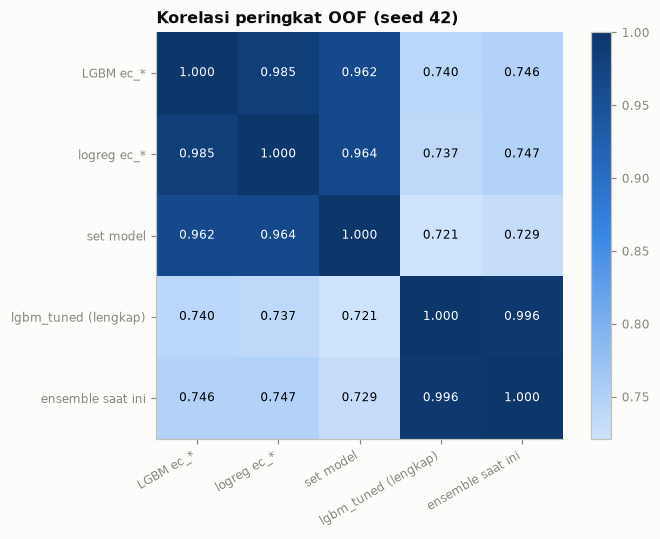

In [6]:
B_REF = M.blend({"lgbm_ec": EC_LGB, "logreg_ec": EC_LR}, y, seeds=list(SEEDS))
B_SET = M.blend({"lgbm_ec": EC_LGB, "set": SET}, y, seeds=list(SEEDS))
display(pl.DataFrame([ks_row("LightGBM ec_* + logreg ec_*", B_REF), ks_row("LightGBM ec_* + set model", B_SET)])
          .with_columns(pl.col(pl.Float64).round(4)))
CMP_B = {"(LGBM ec + set) vs (LGBM ec + logreg ec)": M.compare_runs(B_REF, B_SET, y, SEG)}
display(cmp_table(CMP_B))

REF = M.blend({k: RUNS[k] for k in CORE}, y, seeds=list(SEEDS))          # ensemble saat ini (sub_v4)
names = ["LGBM ec_*", "logreg ec_*", "set model", "lgbm_tuned (lengkap)", "ensemble saat ini"]
vecs = [EC_LGB["oof_by_seed"][42], EC_LR["oof_by_seed"][42], SET["oof_by_seed"][42], LGB["oof_by_seed"][42],
        REF["oof_by_seed"][42]]
C = np.corrcoef([M.rank01(v) for v in vecs])
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(C, cmap=E.SEQ_CMAP, vmin=C.min(), vmax=1)
ax.set_xticks(range(len(names)), names, rotation=30, ha="right"); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{C[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if C[i, j] > (C.min() + 1) / 2 else "black")
ax.grid(False)
ax.set_title("Korelasi peringkat OOF (seed 42)", loc="left")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

## 5. Uji C: stacking bersarang ke model lengkap ⭐

**Konteks dulu:** berapa nilai **seluruh** fitur e-commerce bagi model lengkap? Kita latih `lgbm_tuned` tanpa 50 fitur `ec_*`. Kalau Δ-nya kecil, informasi e-commerce sebagian besar sudah tersedia dari tabel lain, dan set model, sebaik apa pun, hanya bisa menambah sedikit.

In [7]:
NO_EC = M.train_lgb_cv(train, test, [f for f in FEAT if f not in EC], CATS, seeds=SEEDS, params=P_LGB, verbose=False)
display(cmp_table({"lgbm_tuned vs tanpa ec_* (nilai seluruh e-commerce)": M.compare_runs(NO_EC, LGB, y)}))

perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""lgbm_tuned vs tanpa ec_* (nilai seluruh e-commerce)""",0.098,0.096,0.0934,0.0955,0.095,"""3/3""","""jelas"""


**Stacking bersarang:** `lgbm_tuned` dengan satu kolom tambahan, `set_score`. Supaya tidak bocor:
- untuk fold luar *k*, `set_score` baris latih berasal dari CV **dalam** (4 fold) yang hanya memakai baris latih fold *k*. Setiap baris latih diberi skor oleh set model yang tidak melihatnya;
- `set_score` baris validasi fold *k* (dan test) = rata-rata 4 model dalam itu. Model-model itu tidak pernah melihat baris validasi.

Jadi label baris validasi tidak pernah menyentuh set model maupun LightGBM, sama seperti OOF biasa.

In [8]:
done = all((M.PRED_DIR / f"{n}_meta.json").exists() for n in ("lgbm_stack_set_v1", "lgbm_stack_placebo_v1"))
if SKIP_DONE and done:
    STACK, PLACEBO = M.run_from_disk("lgbm_stack_set_v1", y), M.run_from_disk("lgbm_stack_placebo_v1", y)
    STACK_FOLDS = pl.DataFrame(STACK["meta"]["fold_table"])
    print(f"run stacking dimuat dari disk (dilatih {STACK['meta'].get('minutes')} menit)")
else:
    t = time.time()
    STACK, PLACEBO = Q.stacked_lgb_cv(train, test, FEAT, CATS, ARR, folds, STACK_SEEDS, P_LGB, TEST_IDX, device=DEVICE)
    STACK_FOLDS = STACK["folds"]
    mins = round((time.time() - t) / 60, 1)
    for name, r in (("lgbm_stack_set_v1", STACK), ("lgbm_stack_placebo_v1", PLACEBO)):
        M.save_run(name, train, test, r, extra=dict(kind="lgbm_stacking", feature_version="v1+set_score", minutes=mins,
                                                    fold_table=r["folds"].to_dicts()))
print("Porsi gain LightGBM untuk set_score per fold (%):")
display(STACK_FOLDS.with_columns(pl.col(pl.Float64).round(4)))

[stack] seed 42 fold 1: KS 0.5199 (plasebo 0.5184) | gain set_score 17.9% | 363s
[stack] seed 42 fold 2: KS 0.5346 (plasebo 0.5288) | gain set_score 12.7% | 741s
[stack] seed 42 fold 3: KS 0.5396 (plasebo 0.5403) | gain set_score 14.3% | 1119s
[stack] seed 42 fold 4: KS 0.5204 (plasebo 0.5194) | gain set_score 11.4% | 1428s
[stack] seed 42 fold 5: KS 0.5093 (plasebo 0.5123) | gain set_score 15.7% | 1812s
[stack] seed 7 fold 1: KS 0.5275 (plasebo 0.5240) | gain set_score 12.7% | 2122s
[stack] seed 7 fold 2: KS 0.5231 (plasebo 0.5197) | gain set_score 12.3% | 2386s
[stack] seed 7 fold 3: KS 0.5222 (plasebo 0.5194) | gain set_score 12.3% | 2664s
[stack] seed 7 fold 4: KS 0.5288 (plasebo 0.5281) | gain set_score 13.4% | 2953s
[stack] seed 7 fold 5: KS 0.5164 (plasebo 0.5201) | gain set_score 14.5% | 3210s
[stack] seed 2024 fold 1: KS 0.5058 (plasebo 0.5034) | gain set_score 13.8% | 3470s
[stack] seed 2024 fold 2: KS 0.5142 (plasebo 0.5216) | gain set_score 12.6% | 3692s
[stack] seed 2024 f

seed,fold,ks,gain_set_score_pct
i64,i64,f64,f64
42,1,0.5199,17.9338
42,2,0.5346,12.7443
42,3,0.5396,14.2696
42,4,0.5204,11.441
42,5,0.5093,15.6648
7,1,0.5275,12.7332
7,2,0.5231,12.2653
7,3,0.5222,12.2978
7,4,0.5288,13.3947


Noise uji C (maks |Δ plasebo| per seed, minimal 0,0015): 0.0016


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""lgbm_tuned + set_score""",-0.0005,0.0001,0.0013,-0.0003,0.0004,"""2/3""","""tidak"""
"""lgbm_tuned + kolom acak (plasebo)""",-0.0009,-0.0001,0.0016,-0.0009,0.0002,"""1/3""","""tidak"""
"""set_score vs plasebo""",0.0004,0.0001,-0.0002,0.0006,0.0002,"""2/3""","""tidak"""


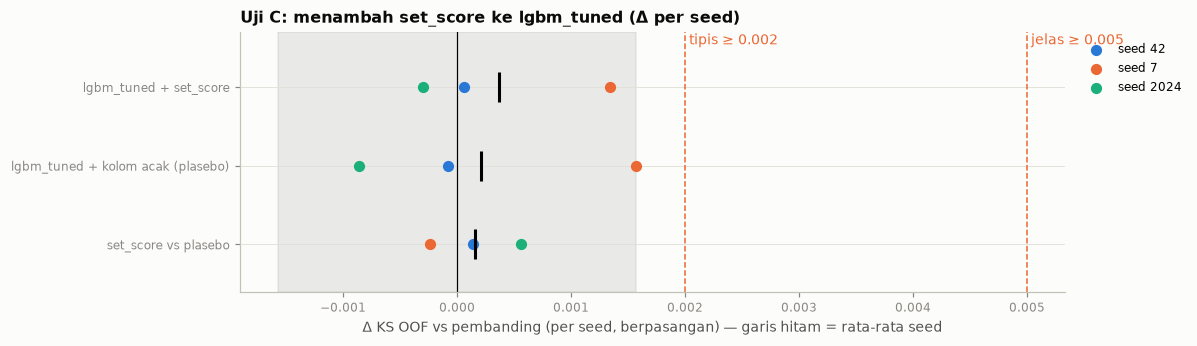

In [9]:
CMP_C = {"lgbm_tuned + set_score": M.compare_runs(LGB, STACK, y, SEG),
         "lgbm_tuned + kolom acak (plasebo)": M.compare_runs(LGB, PLACEBO, y, SEG),
         "set_score vs plasebo": M.compare_runs(PLACEBO, STACK, y, SEG)}
NOISE_C = max(0.0015, float(CMP_C["lgbm_tuned + kolom acak (plasebo)"]["per_seed"]["delta"].abs().max()))
print(f"Noise uji C (maks |Δ plasebo| per seed, minimal 0,0015): {NOISE_C:.4f}")
display(cmp_table(CMP_C, noise=NOISE_C))
M.plot_paired_deltas(CMP_C, list(CMP_C), noise=NOISE_C, title="Uji C: menambah set_score ke lgbm_tuned (Δ per seed)")

In [10]:
print("Per segmen (OOF gabungan): lgbm_tuned + set_score vs lgbm_tuned")
display(CMP_C["lgbm_tuned + set_score"]["per_segment"].with_columns(pl.col(pl.Float64).round(4)))

# Δ per segmen per seed, set_score vs plasebo berdampingan → apakah kenaikan segmen melampaui noise?
rows = []
for g in sorted(set(SEG)):
    m = SEG == g
    for name, r in (("+ set_score", STACK), ("+ plasebo", PLACEBO)):
        d = {s: M.ks_score(y[m], r["oof_by_seed"][s][m]) - M.ks_score(y[m], LGB["oof_by_seed"][s][m]) for s in STACK["seeds"]}
        rows.append(dict(segmen=g, n=int(m.sum()), kolom_tambahan=name, **{f"d_s{s}": v for s, v in d.items()},
                         delta_rata2=np.mean(list(d.values())), seed_naik=f"{sum(v > 0 for v in d.values())}/{len(d)}"))
print("Δ KS per segmen per seed vs lgbm_tuned:")
display(pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4)))

Per segmen (OOF gabungan): lgbm_tuned + set_score vs lgbm_tuned


segment,n,ks_base,ks_baru,delta
str,i64,f64,f64,f64
"""SEMUA""",70000,0.5238,0.5233,-0.0005
"""A_no_history""",21000,0.4952,0.4941,-0.0011
"""B_apps_no_installments""",2688,0.5323,0.5307,-0.0015
"""C_has_installments""",46312,0.5368,0.536,-0.0008


Δ KS per segmen per seed vs lgbm_tuned:


segmen,n,kolom_tambahan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik
str,i64,str,f64,f64,f64,f64,str
"""A_no_history""",21000,"""+ set_score""",0.0022,0.0002,-0.001,0.0005,"""2/3"""
"""A_no_history""",21000,"""+ plasebo""",0.0022,-0.002,-0.0007,-0.0002,"""1/3"""
"""B_apps_no_installments""",2688,"""+ set_score""",-0.0196,-0.0084,0.001,-0.009,"""1/3"""
"""B_apps_no_installments""",2688,"""+ plasebo""",-0.0125,-0.0004,-0.0109,-0.0079,"""0/3"""
"""C_has_installments""",46312,"""+ set_score""",-0.0029,0.0028,-0.0008,-0.0003,"""1/3"""
"""C_has_installments""",46312,"""+ plasebo""",-0.0032,0.0003,-0.0018,-0.0016,"""1/3"""


## 6. Uji D: ensemble saat ini

Pembanding = ensemble saat ini (rata-rata peringkat bobot sama `lgbm_tuned`, `xgb_v1`, `cat_v1`, `logreg_v1`). Kandidat:
1. **+ set model** sebagai anggota ke-5 (bobot sama)
2. **lgbm → lgbm + set_score** (anggota LightGBM diganti versi stacking)
3. **lgbm → plasebo**: kontrol untuk kandidat 2, mengukur noise karena mengganti satu anggota
4. **+ set model, bobot jujur**: bobot dipilih di 4/5 baris, dinilai di 1/5 sisanya (validasi bersarang)

KS OOF ensemble saat ini (3 seed): 0.5254 | noise uji D: 0.0015


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""ensemble + set model""",-0.0039,-0.0032,-0.0031,-0.0033,-0.0032,"""0/3""","""tidak"""
"""ensemble, lgbm → lgbm + set_score""",-0.0002,-0.0004,-0.0003,0.0001,-0.0002,"""1/3""","""tidak"""
"""ensemble, lgbm → plasebo""",0.0002,-0.0011,-0.0005,0.0004,-0.0004,"""1/3""","""tidak"""
"""ensemble + set model, bobot jujur""",-0.0018,-0.0021,-0.0028,-0.0001,-0.0017,"""0/3""","""tidak"""


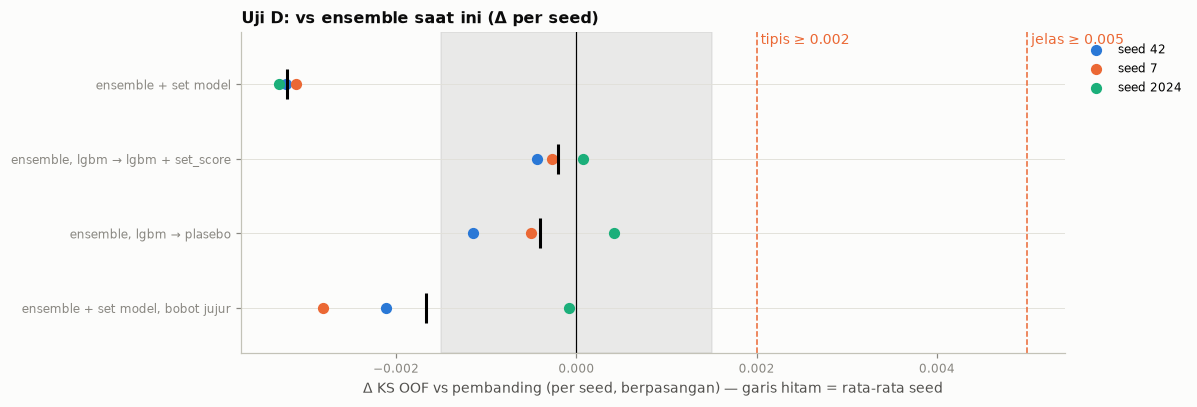

Bobot terpilih per fold (validasi bersarang):


seed,lgbm,xgb,cat,logreg,set
i64,f64,f64,f64,f64,f64
42,0.1,0.1,0.5,0.2,0.1
42,0.2,0.1,0.3,0.4,0.0
42,0.2,0.1,0.4,0.3,0.0
42,0.2,0.1,0.3,0.4,0.0
42,0.1,0.1,0.3,0.4,0.1
7,0.1,0.3,0.4,0.2,0.0
7,0.2,0.3,0.2,0.3,0.0
7,0.2,0.3,0.2,0.3,0.0
7,0.1,0.1,0.3,0.4,0.1


In [11]:
D_SEEDS = [s for s in SEEDS if s in STACK["seeds"]]
REF_D = M.blend({k: RUNS[k] for k in CORE}, y, seeds=D_SEEDS)
BL = {"ensemble + set model": M.blend({**{k: RUNS[k] for k in CORE}, "set": SET}, y, seeds=D_SEEDS),
      "ensemble, lgbm → lgbm + set_score": M.blend({**{k: RUNS[k] for k in CORE}, "lgbm": STACK}, y, seeds=D_SEEDS),
      "ensemble, lgbm → plasebo": M.blend({**{k: RUNS[k] for k in CORE}, "lgbm": PLACEBO}, y, seeds=D_SEEDS)}
SUB_RUNS = {**{k: RUNS[k] for k in CORE}, "set": SET}
BL["ensemble + set model, bobot jujur"] = M.nested_blend(SUB_RUNS, y, "lgbm", seeds=D_SEEDS, step=0.1, max_other=0.9)
CMP_D = {n: M.compare_runs(REF_D, b, y, SEG) for n, b in BL.items()}
NOISE_D = max(0.0015, float(CMP_D["ensemble, lgbm → plasebo"]["per_seed"]["delta"].abs().max()))
print(f"KS OOF ensemble saat ini ({len(D_SEEDS)} seed): {REF_D['ks_oof']:.4f} | noise uji D: {NOISE_D:.4f}")
display(cmp_table(CMP_D, noise=NOISE_D))
M.plot_paired_deltas(CMP_D, list(CMP_D), noise=NOISE_D, title="Uji D: vs ensemble saat ini (Δ per seed)")
print("Bobot terpilih per fold (validasi bersarang):")
display(BL["ensemble + set model, bobot jujur"]["fold_weights"])

## 7. Keputusan

In [13]:
pool = [n for n in CMP_D if n != "ensemble, lgbm → plasebo" and CMP_D[n]["per_seed"].height >= 3]
best = max(pool, key=lambda n: CMP_D[n]["delta_oof"]) if pool else None
V_C = M.verdict(CMP_C["lgbm_tuned + set_score"], noise=NOISE_C) if CMP_C["lgbm_tuned + set_score"]["per_seed"].height >= 3 else "perlu 3 seed"
print(f"Uji C (penentu): {V_C}")
if best:
    V_D = M.verdict(CMP_D[best], noise=NOISE_D)
    print(f"Uji D kandidat terbaik: {best} | Δ OOF gabungan {CMP_D[best]['delta_oof']:+.4f} | keputusan: {V_D}")
    if V_D in ("jelas", "tipis") and best != "ensemble + set model, bobot jujur":
        pick = BL[best]
        pick.update(features=[], params=pick.get("weights", {}), best_iters=[0])
        M.save_run("ensemble_set_v1", train, test, pick, extra=dict(blend=best, delta_vs_ensemble_v1=CMP_D[best]["delta_oof"]))
        ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
        M.make_submission(test["application_id"], pick["test_pred"], ss, M.SUB_DIR / "sub_v6_ensemble_set.csv")
    elif V_D in ("jelas", "tipis"):
        print("Yang lolos adalah bobot jujur; bobotnya berbeda tiap fold, jadi perlu dibahas dulu sebelum dibuat submission.")
    else:
        print("Tidak lolos → ensemble saat ini (sub_v4) tetap dipakai.")

Uji C (penentu): tidak
Uji D kandidat terbaik: ensemble, lgbm → lgbm + set_score | Δ OOF gabungan -0.0002 | keputusan: tidak
Tidak lolos → ensemble saat ini (sub_v4) tetap dipakai.
